# Hierarchical clustering dendrogram: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/cluster/plot_agglomerative_dendrogram.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/cluster/plot_agglomerative_dendrogram.html)).

**Scenario:** `AgglomerativeClustering(distance_threshold=0, n_clusters=None)` builds the full Ward
tree of the bundled iris data (150 x 4); `children_` and `distances_` feed SciPy's `dendrogram`.
Beyond the example, the notebook compares, on the same data, the four linkages with `n_clusters=3`
(labels, `children_`, `distances_` with `compute_distances=True`), a positive `distance_threshold`,
non-Euclidean metrics (`manhattan`, `cosine`), the functional `ward_tree` / `linkage_tree`, `FeatureAgglomeration`
(`transform`, `inverse_transform`), a Float32 fit, and `clone` + `set_params` refits.

**Adaptations:** none in the data. Moxie labels/children are Int64 (sklearn: int64 children, intp labels),
`distances_` is an `Optional` Float64 array, and `n_clusters=None` is `Optional[Int]` (documented
in `families/cluster/algorithms/agglomerative/docs/api.md`). The dendrogram is drawn with SciPy
in Python from Moxie's `children_` / `distances_` (plotting only).

**Determinism:** deterministic. Iris contains duplicate rows, so several merges happen at distance 0;
both implementations break those ties identically if `children_` matches exactly, which is checked.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("cluster/plot_agglomerative_dendrogram")

## 1. scikit-learn (Python reference)

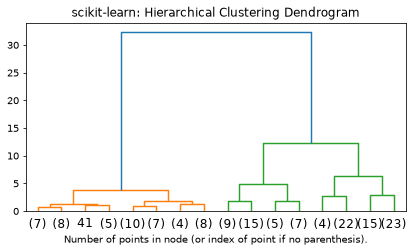

In [2]:
import numpy as np
from matplotlib import pyplot as plt
from scipy.cluster.hierarchy import dendrogram

from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris


def plot_dendrogram(model, **kwargs):
    # Create linkage matrix and then plot the dendrogram

    # create the counts of samples under each node
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack(
        [model.children_, model.distances_, counts]
    ).astype(float)

    # Plot the corresponding dendrogram
    dendrogram(linkage_matrix, **kwargs)


iris = load_iris()
X = iris.data

# setting distance_threshold=0 ensures we compute the full tree.
model = AgglomerativeClustering(distance_threshold=0, n_clusters=None)

model = model.fit(X)
plt.figure(figsize=(7, 3.5), dpi=70)
plt.title("scikit-learn: Hierarchical Clustering Dendrogram")
# plot the top three levels of the dendrogram
plot_dendrogram(model, truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()

In [3]:
# Beyond the example: every linkage, metrics, thresholds, tree helpers, features, Float32, clone.
from sklearn.base import clone
from sklearn.cluster import FeatureAgglomeration, linkage_tree, ward_tree

sk = {"full": model}
for linkage in ("ward", "complete", "average", "single"):
    sk[linkage] = AgglomerativeClustering(n_clusters=3, linkage=linkage, compute_distances=True).fit(X)
sk["manhattan_average"] = AgglomerativeClustering(n_clusters=3, linkage="average", metric="manhattan").fit(X)
sk["cosine_complete"] = AgglomerativeClustering(n_clusters=3, linkage="complete", metric="cosine").fit(X)
sk["threshold"] = AgglomerativeClustering(n_clusters=None, distance_threshold=3.0).fit(X)
sk["float32"] = AgglomerativeClustering(n_clusters=3, compute_distances=True).fit(X.astype(np.float32))
sk["clone_refit"] = clone(sk["ward"]).set_params(linkage="average", n_clusters=4).fit(X)
wt = ward_tree(X, return_distance=True)
lt = linkage_tree(X, linkage="single", affinity="manhattan", return_distance=True)
fa = FeatureAgglomeration(n_clusters=2).fit(X)
fa_t = fa.transform(X)
fa_inv = fa.inverse_transform(fa_t)
for k, m in sk.items():
    print(f"{k:18s} n_clusters_={m.n_clusters_} sizes={np.bincount(m.labels_)}")
print("FeatureAgglomeration labels_:", fa.labels_)
nb.share(X=X, X32=X.astype(np.float32))

full               n_clusters_=150 sizes=[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1]
ward               n_clusters_=3 sizes=[64 50 36]
complete           n_clusters_=3 sizes=[72 50 28]
average            n_clusters_=3 sizes=[64 50 36]
single             n_clusters_=3 sizes=[98 50  2]
manhattan_average  n_clusters_=3 sizes=[63 50 37]
cosine_complete    n_clusters_=3 sizes=[50 74 26]
threshold          n_clusters_=6 sizes=[38 26 29 12 24 21]
float32            n_clusters_=3 sizes=[64 50 36]
clone_refit        n_clusters_=4 sizes=[36 50 60  4]
FeatureAgglomeration labels_: [1 0 0 0]


## 2. Moxie (native Mojo)

In [4]:
%%mojo agglomerative
from moxie.base import clone
from moxie.cluster import AgglomerativeClustering, FeatureAgglomeration, linkage_tree, ward_tree
from moxie_nb_io import load, save


def main() raises:
    var X = load("X")
    var full = AgglomerativeClustering(None, distance_threshold=0.0)
    _ = full.fit(X)
    save("full_labels", full.labels_)
    save("full_children", full.children_)
    save("full_distances", full.distances_.value())
    print("full tree: n_clusters_ =", full.n_clusters_, "n_leaves_ =", full.n_leaves_,
          "n_connected_components_ =", full.n_connected_components_)

    var linkages = ["ward", "complete", "average", "single"]
    for linkage in linkages:
        var m = AgglomerativeClustering(3, linkage=linkage, compute_distances=True)
        _ = m.fit(X)
        save(linkage + "_labels", m.labels_)
        save(linkage + "_children", m.children_)
        save(linkage + "_distances", m.distances_.value())

    var manhattan = AgglomerativeClustering(3, linkage="average", metric="manhattan")
    save("manhattan_average_labels", manhattan.fit_predict(X))
    var cosine = AgglomerativeClustering(3, linkage="complete", metric="cosine")
    save("cosine_complete_labels", cosine.fit_predict(X))
    var threshold = AgglomerativeClustering(None, distance_threshold=3.0)
    _ = threshold.fit(X)
    save("threshold_labels", threshold.labels_)
    print("threshold=3: n_clusters_ =", threshold.n_clusters_)

    var m32 = AgglomerativeClustering[DType.float32](3, compute_distances=True)
    _ = m32.fit(load[DType.float32]("X32"))
    save("float32_labels", m32.labels_)
    save("float32_distances", m32.distances_.value())

    var base = AgglomerativeClustering(3, linkage="ward", compute_distances=True)
    _ = base.fit(X)
    var refit = clone(base)
    _ = refit.set_params(linkage=String("average"), n_clusters=Optional[Optional[Int]](Optional[Int](4)))
    _ = refit.fit(X)
    save("clone_refit_labels", refit.labels_)

    var wt = ward_tree(X, return_distance=True)
    save("ward_tree_children", wt.children)
    save("ward_tree_distances", wt.distances.value())
    var lt = linkage_tree(X, linkage="single", affinity="manhattan", return_distance=True)
    save("linkage_tree_children", lt.children)
    save("linkage_tree_distances", lt.distances.value())

    var fa = FeatureAgglomeration(2)
    _ = fa.fit(X)
    var pooled = fa.transform(X)
    save("fa_labels", fa.labels_)
    save("fa_transform", pooled)
    save("fa_inverse", fa.inverse_transform(pooled))

full tree: n_clusters_ = 150 n_leaves_ = 150 n_connected_components_ = 1
threshold=3: n_clusters_ = 6


## 3. Side by side and parity

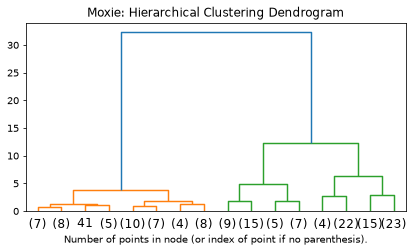

In [5]:
mx = nb.results["agglomerative"]

class Fitted:  # minimal view so the example's plot_dendrogram draws Moxie's tree
    def __init__(self, children, distances, labels):
        self.children_, self.distances_, self.labels_ = children, distances, labels

plt.figure(figsize=(7, 3.5), dpi=70)
plt.title("Moxie: Hierarchical Clustering Dendrogram")
plot_dendrogram(Fitted(mx["full_children"], mx["full_distances"], mx["full_labels"]), truncate_mode="level", p=3)
plt.xlabel("Number of points in node (or index of point if no parenthesis).")
plt.show()
moxie_nb.side_by_side(sklearn=np.column_stack([model.children_, model.distances_])[-5:],
                      moxie=np.column_stack([mx["full_children"], mx["full_distances"]])[-5:])

dist_reason = ("Ward/linkage distances are Float64 in both; Lance-Williams updates and Euclidean "
               "distances are evaluated in a different order than SciPy's C code")
nb.compare("full tree children_", model.children_, mx["full_children"], exact=True)
nb.compare("full tree distances_", model.distances_, mx["full_distances"], rtol=1e-12, atol=1e-13, reason=dist_reason)
nb.compare("full tree labels_ (one per sample)", model.labels_, mx["full_labels"], exact=True)
for linkage in ("ward", "complete", "average", "single"):
    nb.compare(f"{linkage} labels_", sk[linkage].labels_, mx[f"{linkage}_labels"], exact=True)
    nb.compare(f"{linkage} children_", sk[linkage].children_, mx[f"{linkage}_children"], exact=True)
    nb.compare(f"{linkage} distances_", sk[linkage].distances_, mx[f"{linkage}_distances"],
               rtol=1e-12, atol=1e-13, reason=dist_reason)
nb.compare("average/manhattan labels_", sk["manhattan_average"].labels_, mx["manhattan_average_labels"], exact=True)
nb.compare("complete/cosine labels_", sk["cosine_complete"].labels_, mx["cosine_complete_labels"], exact=True)
nb.compare("distance_threshold=3 labels_", sk["threshold"].labels_, mx["threshold_labels"], exact=True)
nb.compare("Float32 labels_", sk["float32"].labels_, mx["float32_labels"], exact=True)
nb.compare("Float32 distances_", sk["float32"].distances_, mx["float32_distances"], rtol=1e-12, atol=1e-13,
           reason="both promote Float32 input to Float64 for the unstructured tree; " + dist_reason)
nb.compare("clone + set_params(average, 4) refit labels_", sk["clone_refit"].labels_, mx["clone_refit_labels"], exact=True)
nb.compare("ward_tree children", wt[0], mx["ward_tree_children"], exact=True)
nb.compare("ward_tree distances", wt[4], mx["ward_tree_distances"], rtol=1e-12, atol=1e-13, reason=dist_reason)
nb.compare("linkage_tree(single, manhattan) children", lt[0], mx["linkage_tree_children"], exact=True)
nb.compare("linkage_tree(single, manhattan) distances", lt[4], mx["linkage_tree_distances"], rtol=1e-12, atol=1e-13, reason=dist_reason)
nb.compare("FeatureAgglomeration labels_", fa.labels_, mx["fa_labels"], exact=True)
nb.compare("FeatureAgglomeration transform", fa_t, mx["fa_transform"], rtol=1e-14, atol=1e-14,
           reason="feature means over two or three columns; summation order can differ by one ulp")
nb.compare("FeatureAgglomeration inverse_transform", fa_inv, mx["fa_inverse"], rtol=1e-14, atol=1e-14,
           reason="inverse repeats the pooled means");

### Connectivity constraints

The example's sibling `plot_ward_structured_vs_unstructured.py` and `plot_coin_ward_segmentation.py`
pass a sparse `connectivity` graph. Moxie defers connectivity-constrained linkage
(`families/cluster/docs/scope.md`); a dense connectivity mask raises clearly.

In [6]:
%%mojo agglomerative_connectivity --expect-fail
from moxie.cluster import AgglomerativeClustering
from moxie_nb_io import load
import numojo as nm


def main() raises:
    var X = load("X")
    var conn = nm.ones[DType.float64](nm.Shape(X.shape[0], X.shape[0]))
    var model = AgglomerativeClustering(3, connectivity=conn)
    _ = model.fit(X)

Expected failure (unsupported in Moxie):
compilation failed
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_agglomerative_dendrogram/agglomerative_connectivity.mojo:9:57: error: value of type 'NDArray' cannot be implicitly copied, it does not conform to 'ImplicitlyCopyable'
    var model = AgglomerativeClustering(3, connectivity=conn)
                                                        ^~~~
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_agglomerative_dendrogram/agglomerative_connectivity.mojo:9:57: note: consider transferring the value with '^'
    var model = AgglomerativeClustering(3, connectivity=conn)
                                                        ^
                                                            ^
/home/strgenix/postdoc/projects/mojods/porting-sklearn/moxie/builds/notebooks/cluster/plot_agglomerative_dendrogram/agglomerative_connectivity.mojo:9:57: note: you can copy it 

In [7]:
nb.note("connectivity=...", "GAP", "connectivity-constrained linkage is deferred (docs/scope.md); "
        "blocks plot_ward_structured_vs_unstructured, plot_coin_ward_segmentation, "
        "plot_agglomerative_clustering (kneighbors_graph), plot_feature_agglomeration_vs_univariate_selection")
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
full tree children_,PASS,"(149, 2)","(149, 2)",,,exact,0 mismatches,
full tree distances_,PASS,"(149,)","(149,)",0,0,"rtol=1e-12, atol=1e-13",,Ward/linkage distances are Float64 in both; Lance-Williams updates and Euclidean distances are evaluated in a different order than SciPy's C code
full tree labels_ (one per sample),PASS,"(150,)","(150,)",,,exact,0 mismatches,
ward labels_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
ward children_,PASS,"(149, 2)","(149, 2)",,,exact,0 mismatches,
ward distances_,PASS,"(149,)","(149,)",0,0,"rtol=1e-12, atol=1e-13",,Ward/linkage distances are Float64 in both; Lance-Williams updates and Euclidean distances are evaluated in a different order than SciPy's C code
complete labels_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
complete children_,PASS,"(149, 2)","(149, 2)",,,exact,0 mismatches,
complete distances_,PASS,"(149,)","(149,)",0,0,"rtol=1e-12, atol=1e-13",,Ward/linkage distances are Float64 in both; Lance-Williams updates and Euclidean distances are evaluated in a different order than SciPy's C code
average labels_,PASS,"(150,)","(150,)",,,exact,0 mismatches,
